# Embedding your own data with the histology-guided autoencoder

Applies the encoder from *Slide-level batch structure limits histology-guided supervision of
transcriptomic foundation models* ([bioRxiv](https://doi.org/10.64898/2026.09.30.755585))
to scanpy's [PBMC 3k](https://scanpy.readthedocs.io/en/stable/generated/scanpy.datasets.pbmc3k.html).

![Model overview](../docs/overview.png)

The model was trained to predict H&E ([Midnight](https://huggingface.co/kaiko-ai/midnight))
embeddings from [Geneformer](https://huggingface.co/ctheodoris/Geneformer) embeddings.
Inference needs only gene expression:

$$z = \mathrm{LayerNorm}\big(\mathrm{Encoder}(\text{Geneformer}(\text{counts}))\big) \in \mathbb{R}^{128}$$

Requires `pip install -r requirements.txt` from the repository root; runs on CPU in a few
minutes.

## Setup

In [1]:
import json
import os
import warnings
from pathlib import Path

os.environ.setdefault("JAX_PLATFORMS", "cpu")  # scib-metrics runs on JAX; CPU is enough
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import torch
import torch.nn as nn
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file
from scib_metrics.benchmark import Benchmarker
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

HF_REPO = "umcconnell/vgtfm"
LOCAL_DIR = os.environ.get("VGTFM_RELEASE_DIR")  # optional local copy of HF_REPO
SEED = 0


def fetch(filename: str) -> Path:
    if LOCAL_DIR:
        return Path(LOCAL_DIR) / filename
    return Path(hf_hub_download(HF_REPO, filename))


torch.manual_seed(SEED)
sc.settings.verbosity = 1

## 1. Load the autoencoder

The architecture, as in `vgtfm.models.ae`:

In [2]:
def mlp(sizes: list[int], dropout: float) -> nn.Sequential:
    layers: list[nn.Module] = []
    for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:])):
        layers.append(nn.Linear(a, b))
        if i < len(sizes) - 2:  # no activation after the last layer
            layers += [nn.BatchNorm1d(b), nn.GELU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
    return nn.Sequential(*layers)


class Autoencoder(nn.Module):
    def __init__(self, encoder_sizes: list[int], decoder_sizes: list[int], dropout: float):
        super().__init__()
        self.encoder = mlp(encoder_sizes, dropout)
        self.decoder = mlp(decoder_sizes, dropout)  # predicts the Midnight H&E embedding
        self.encoder_norm = nn.LayerNorm(encoder_sizes[-1])

    @torch.no_grad()
    def embed(self, x: torch.Tensor) -> torch.Tensor:
        # The deployed representation; the decoder is not used.
        return self.encoder_norm(self.encoder(x))


arch = json.loads(fetch("config.json").read_text())["architecture"]
model = Autoencoder(arch["encoder_sizes"], arch["decoder_sizes"], arch["dropout"])
model.load_state_dict(load_file(fetch("model.safetensors")), strict=True)
model.eval()  # BatchNorm uses its running statistics, dropout is off
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

4,499,584 parameters


## 2. Load Geneformer embeddings for PBMC 3k

Precomputed Geneformer embeddings ship with the model (one row per cell barcode, see
[Embedding your own data](#Embedding-your-own-data) to compute your own). Cell-type labels
come from scanpy's processed PBMC 3k.

In [3]:
features = pd.read_parquet(fetch("examples/pbmc3k_geneformer.parquet")).set_index("spot_id")
assert features.shape[1] == arch["d_gene"], "input width does not match the encoder"

adata = sc.datasets.pbmc3k_processed()  # 2,638 annotated cells
missing = adata.obs_names.difference(features.index)
assert missing.empty, f"{len(missing)} annotated cells have no Geneformer embedding"
adata.obsm["X_geneformer"] = features.loc[adata.obs_names].to_numpy(np.float32)
adata.obs["cell_type"] = adata.obs["louvain"].astype("category")

print(f"{adata.n_obs:,} cells, Geneformer embedding {adata.obsm['X_geneformer'].shape[1]}-d")
adata.obs["cell_type"].value_counts().to_frame("cells")

2,638 cells, Geneformer embedding 1152-d


,cells
cell_type,
CD4 T cells,1144
CD14+ Monocytes,480
B cells,342
CD8 T cells,316
NK cells,154
FCGR3A+ Monocytes,150
Dendritic cells,37
Megakaryocytes,15


## 3. Embed with the encoder

In [4]:
X = torch.from_numpy(adata.obsm["X_geneformer"])
adata.obsm["X_vgtfm"] = model.embed(X).numpy()
print(f"encoder embedding {adata.obsm['X_vgtfm'].shape}")

encoder embedding (2638, 128)


`adata.obsm["X_vgtfm"]` can be used like any other embedding. The rest of the notebook
compares it with the Geneformer input.

## 4. UMAP

Colours show lineages, labels show cell types.

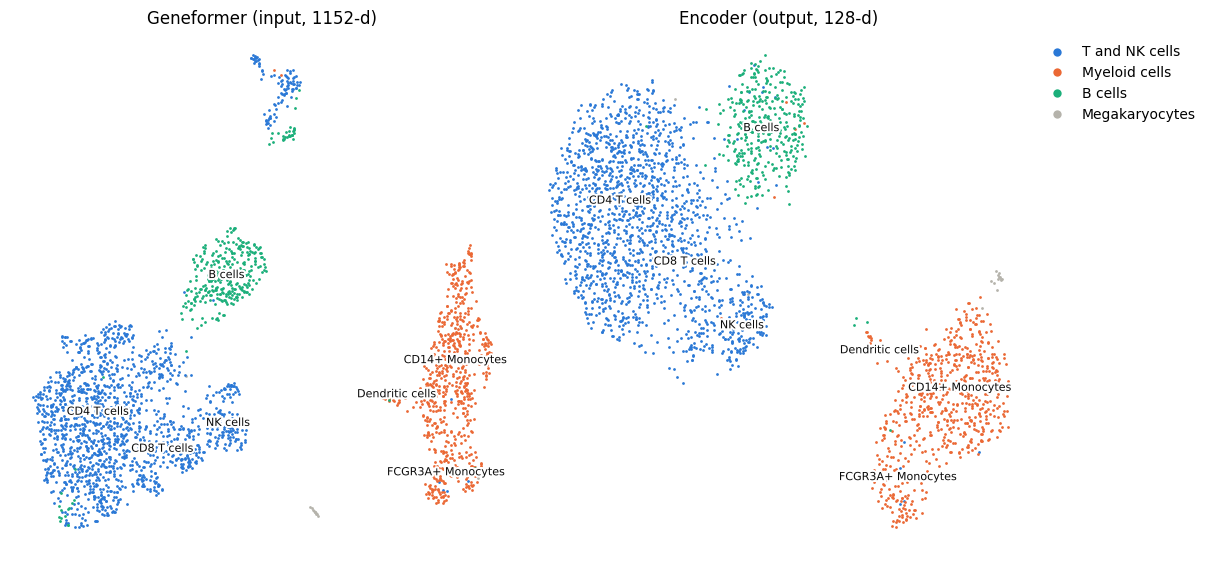

In [5]:
EMBEDDINGS = {
    "X_geneformer": f"Geneformer (input, {arch['d_gene']}-d)",
    "X_vgtfm": f"Encoder (output, {arch['d_latent']}-d)",
}
LINEAGE = {
    "CD4 T cells": "T and NK cells", "CD8 T cells": "T and NK cells", "NK cells": "T and NK cells",
    "CD14+ Monocytes": "Myeloid cells", "FCGR3A+ Monocytes": "Myeloid cells",
    "Dendritic cells": "Myeloid cells", "B cells": "B cells", "Megakaryocytes": "Megakaryocytes",
}
LINEAGE_COLORS = {"T and NK cells": "#2a78d6", "Myeloid cells": "#eb6834", "B cells": "#1baf7a",
                  "Megakaryocytes": "#b5b3ab"}
UNLABELLED = {"Megakaryocytes"}  # a label would hide their 15 points; the legend names them
adata.obs["lineage"] = adata.obs["cell_type"].map(LINEAGE).astype(str)

for key in EMBEDDINGS:
    sc.pp.neighbors(adata, use_rep=key, key_added=key, random_state=SEED)
    sc.tl.umap(adata, neighbors_key=key, random_state=SEED)
    adata.obsm[f"X_umap_{key}"] = adata.obsm.pop("X_umap")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), constrained_layout=True)
for ax, (key, title) in zip(axes, EMBEDDINGS.items()):
    xy = adata.obsm[f"X_umap_{key}"]
    for lineage, color in LINEAGE_COLORS.items():
        mask = (adata.obs["lineage"] == lineage).to_numpy()
        ax.scatter(*xy[mask].T, s=4, c=color, label=lineage, linewidths=0,
                   zorder=1 if lineage in UNLABELLED else 2)  # grey behind the colours
    for cell_type, idx in adata.obs.groupby("cell_type", observed=True).indices.items():
        if cell_type in UNLABELLED:
            continue
        x, y = np.median(xy[idx], axis=0)
        ax.text(x, y, cell_type, fontsize=8, ha="center", va="center", color="#0b0b0b", zorder=3,
                path_effects=[pe.withStroke(linewidth=3, foreground="white")])
    ax.set_title(title)
    ax.set_axis_off()
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False, markerscale=3)
plt.show()

## 5. How well do the embeddings separate cell types?

* **kNN macro-F1:** 5-nearest-neighbour classifier, 5-fold cross-validation.
* **Effective rank:** number of dimensions carrying variance (Roy & Vetterli).
* **scIB bio-conservation** from [scib-metrics](https://scib-metrics.readthedocs.io).

In [6]:
def knn_macro_f1(Z: np.ndarray, labels: np.ndarray) -> float:
    probe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    return f1_score(labels, cross_val_predict(probe, Z, labels, cv=folds), average="macro")


def effective_rank(Z: np.ndarray) -> float:
    s2 = np.linalg.svd(Z - Z.mean(0), compute_uv=False).astype(np.float64) ** 2
    p = np.clip(s2 / s2.sum(), 1e-20, None)
    return float(np.exp(-(p * np.log(p)).sum()))


labels = adata.obs["cell_type"].to_numpy()
summary = pd.DataFrame(
    {
        EMBEDDINGS[key]: {
            "dimensions": adata.obsm[key].shape[1],
            "effective rank": effective_rank(adata.obsm[key]),
            "kNN macro-F1": knn_macro_f1(adata.obsm[key], labels),
        }
        for key in EMBEDDINGS
    }
).T
summary.style.format({"dimensions": "{:.0f}", "effective rank": "{:.1f}", "kNN macro-F1": "{:.3f}"})

,dimensions,effective rank,kNN macro-F1
"Geneformer (input, 1152-d)",1152,54.3,0.899
"Encoder (output, 128-d)",128,26.7,0.838


In [7]:
adata.obs["batch"] = "pbmc3k"  # scib-metrics requires a batch column, even a constant one
bm = Benchmarker(
    adata,
    batch_key="batch",
    label_key="cell_type",
    embedding_obsm_keys=list(EMBEDDINGS),
    batch_correction_metrics=None,
    progress_bar=False,
)
bm.benchmark()

scib = bm.get_results(min_max_scale=False).drop(index="Metric Type").drop(columns="Bio conservation")
scib = scib.astype(float).rename(index=EMBEDDINGS).rename_axis(None)
scib.style.format("{:.3f}")

,Isolated labels,KMeans NMI,KMeans ARI,Silhouette label,cLISI
"Geneformer (input, 1152-d)",0.556,0.612,0.608,0.537,0.992
"Encoder (output, 128-d)",0.554,0.541,0.369,0.535,0.983


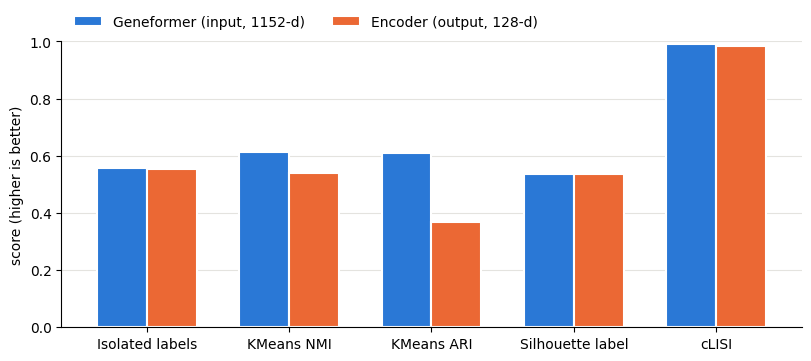

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
scib.T.plot.bar(ax=ax, rot=0, width=0.7, color=["#2a78d6", "#eb6834"],
                edgecolor="white", linewidth=1.5)  # thin white gap between adjacent bars
ax.set_ylabel("score (higher is better)")
ax.set_ylim(0, 1)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
plt.show()

## Notes

* The model was trained on Visium spots from tumour tissue, not on blood single cells.
* PBMC 3k is a single batch. For multi-sample data, set `batch_key` and remove
  `batch_correction_metrics=None` to also compute batch-correction metrics.

## Embedding your own data

Input: an `.h5ad` with raw counts and Ensembl gene ids in `.var`. Once, from the
repository root:

```bash
conda env create -f envs/geneformer.yaml
conda run -n vgtfm-geneformer python envs/geneformer_install.py
```

Then:

```bash
conda run -n vgtfm-geneformer python -m vgtfm.embed.gene_fm \
    --model geneformer --h5ad my_data.h5ad --out my_data_geneformer.parquet \
    --gene-id-column gene_ids
```

and load `my_data_geneformer.parquet` in section 2. The PBMC 3k input was
`sc.datasets.pbmc3k()`.

## Citation

```bibtex
@article{McConnell2026.09.30.755585,
  author    = {McConnell, Ulysse and Nonchev, Kalin and Koelzer, Viktor H and R{\"a}tsch, Gunnar},
  title     = {Slide-level batch structure limits histology-guided supervision of transcriptomic foundation models},
  journal   = {bioRxiv},
  year      = {2026},
  elocation-id = {2026.09.30.755585},
  doi       = {10.64898/2026.09.30.755585},
  publisher = {Cold Spring Harbor Laboratory},
  URL       = {https://www.biorxiv.org/content/early/2026/10/05/2026.09.30.755585}
}
```